# Q-Learning Algorithm Demo

Simple demonstration of Q-Learning using a Grid World environment.

In [18]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import random
from algorithm import QLearningAgent

# Set random seed
np.random.seed(42)
random.seed(42)

In [19]:
class GridWorld:
    """Simple 5x5 Grid World Environment"""
    
    def __init__(self):
        self.size = 5
        self.start = (0, 0)
        self.goal = (4, 4)
        self.obstacles = [(1, 1), (2, 3), (3, 1)]
        self.actions = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}  # Up, Down, Left, Right
        self.n_actions = 4
        self.n_states = 25
        self.pos = self.start
    
    def reset(self):
        self.pos = self.start
        return self.pos[0] * self.size + self.pos[1]
    
    def step(self, action):
        move = self.actions[action]
        new_pos = (self.pos[0] + move[0], self.pos[1] + move[1])
        
        # Check boundaries
        if new_pos[0] < 0 or new_pos[0] >= self.size or new_pos[1] < 0 or new_pos[1] >= self.size:
            reward, done = -0.2, False  # Hit wall
        elif new_pos in self.obstacles:
            self.pos = new_pos
            reward, done = -1.0, False  # Hit obstacle
        elif new_pos == self.goal:
            self.pos = new_pos
            reward, done = 10.0, True  # Reached goal
        else:
            self.pos = new_pos
            reward, done = -0.1, False  # Normal move
        
        state = self.pos[0] * self.size + self.pos[1]
        return state, reward, done, {}
    
    def render(self):
        """Print grid"""
        for i in range(self.size):
            row = []
            for j in range(self.size):
                if (i, j) == self.pos:
                    row.append('A')
                elif (i, j) == self.goal:
                    row.append('G')
                elif (i, j) in self.obstacles:
                    row.append('X')
                else:
                    row.append('.')
            print(' '.join(row))
        print()

In [20]:
# Create environment and agent
env = GridWorld()
agent = QLearningAgent(
    n_states=env.n_states,
    n_actions=env.n_actions,
    learning_rate=0.1,
    discount_factor=0.95
)

print("Environment created:")
env.render()
print("Legend: A=Agent, G=Goal, X=Obstacle, .=Empty")

Environment created:
A . . . .
. X . . .
. . . X .
. X . . .
. . . . G

Legend: A=Agent, G=Goal, X=Obstacle, .=Empty


In [21]:
# Train the agent
print("Training...")
agent.train(env, n_episodes=500)
print("Training complete!")

Training...
Episode 100: Avg Reward=1.12, Epsilon=0.606
Episode 200: Avg Reward=7.64, Epsilon=0.367
Episode 300: Avg Reward=8.56, Epsilon=0.222
Episode 400: Avg Reward=8.87, Epsilon=0.135
Episode 500: Avg Reward=9.10, Epsilon=0.082
Training completed!
Training complete!


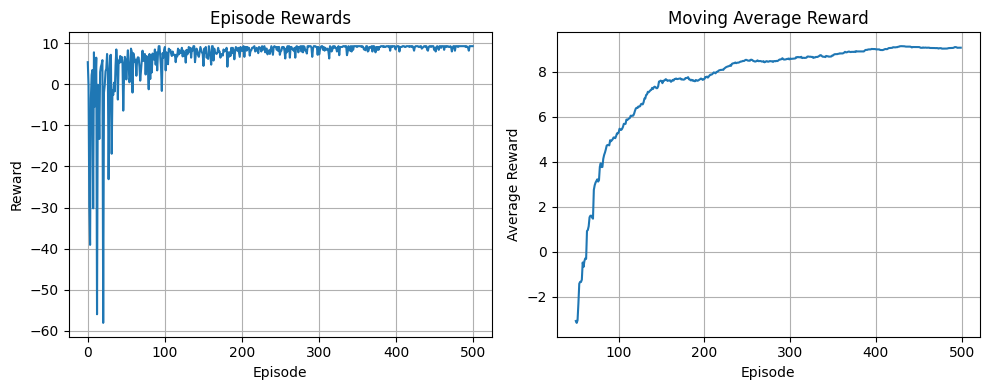

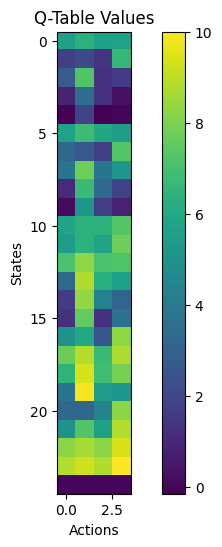

In [22]:
# Show training progress
agent.plot_training_progress()

# Show Q-table
agent.plot_q_table()

In [23]:
# Test the trained agent
results = agent.evaluate(env, n_episodes=100)
print(f"Test Results:")
print(f"- Average reward: {results['mean_reward']:.1f}")
print(f"- Success rate: {results['success_rate']:.1%}")

# Show learned policy
policy = agent.get_policy()
actions = ['Up', 'Down', 'Left', 'Right']
print("\nLearned Policy (state -> action):")
for i in range(5):
    for j in range(5):
        state = i * 5 + j
        action = actions[policy[state]]
        print(f"({i},{j}): {action[:1]}", end="  ")
    print()

Test Results:
- Average reward: 9.3
- Success rate: 100.0%

Learned Policy (state -> action):
(0,0): D  (0,1): R  (0,2): D  (0,3): D  (0,4): D  
(1,0): D  (1,1): R  (1,2): D  (1,3): D  (1,4): D  
(2,0): R  (2,1): R  (2,2): D  (2,3): D  (2,4): D  
(3,0): D  (3,1): R  (3,2): D  (3,3): D  (3,4): D  
(4,0): R  (4,1): R  (4,2): R  (4,3): R  (4,4): U  


In [24]:
# Watch the agent solve the environment
print("Watching trained agent:")
state = env.reset()
env.render()

for step in range(15):
    action = agent.get_action(state, training=False)
    state, reward, done, _ = env.step(action)
    
    print(f"Step {step + 1}: Action={['Up','Down','Left','Right'][action]}, Reward={reward:.1f}")
    env.render()
    
    if done:
        print(f"Goal reached in {step + 1} steps!")
        break

Watching trained agent:
A . . . .
. X . . .
. . . X .
. X . . .
. . . . G

Step 1: Action=Down, Reward=-0.1
. . . . .
A X . . .
. . . X .
. X . . .
. . . . G

Step 2: Action=Down, Reward=-0.1
. . . . .
. X . . .
A . . X .
. X . . .
. . . . G

Step 3: Action=Right, Reward=-0.1
. . . . .
. X . . .
. A . X .
. X . . .
. . . . G

Step 4: Action=Right, Reward=-0.1
. . . . .
. X . . .
. . A X .
. X . . .
. . . . G

Step 5: Action=Down, Reward=-0.1
. . . . .
. X . . .
. . . X .
. X A . .
. . . . G

Step 6: Action=Down, Reward=-0.1
. . . . .
. X . . .
. . . X .
. X . . .
. . A . G

Step 7: Action=Right, Reward=-0.1
. . . . .
. X . . .
. . . X .
. X . . .
. . . A G

Step 8: Action=Right, Reward=10.0
. . . . .
. X . . .
. . . X .
. X . . .
. . . . A

Goal reached in 8 steps!


In [25]:
# Save model
agent.save_model('q_model.pkl')

print("\n🎉 Q-Learning Demo Complete!")
print("\nKey Concepts Demonstrated:")
print("✓ Epsilon-greedy exploration")
print("✓ Q-value updates using Bellman equation")
print("✓ Policy extraction from Q-table")
print("✓ Learning optimal paths through trial and error")

Model saved to q_model.pkl

🎉 Q-Learning Demo Complete!

Key Concepts Demonstrated:
✓ Epsilon-greedy exploration
✓ Q-value updates using Bellman equation
✓ Policy extraction from Q-table
✓ Learning optimal paths through trial and error
